In [ ]:
# Uncomment kode di bawah ini jika terdapat masalah dengan Java di Windows

# import os
# import sys

# JAVA = r"C:\path\to\your\java\jdk" # Ganti dengan path JDK yang sesuai

# os.environ["JAVA_HOME"] = JAVA
# os.environ["PATH"] = os.path.join(JAVA, "bin") + os.path.pathsep + os.environ.get("PATH", "")
# os.environ["PYSPARK_PYTHON"] = sys.executable
# os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

In [25]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, length, trim, when
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .appName("AmazonReviewsPolarity") \
    .config("spark.driver.memory", "4g") \
    .master("local[*]") \
    .getOrCreate()

df = spark.read.csv("../datasets/test.csv", header=True, inferSchema=True)
df = df.toDF("label", "title", "text")

In [ ]:
# Handle Missing Values

for kolom in df.columns:
    total_null = df.filter(col(kolom).isNull()).count()
    print(f"Kolom '{kolom}': {total_null} data kosong")

df = df.dropna()

for kolom in df.columns:
    total_null = df.filter(col(kolom).isNull()).count()
    print(f"Kolom '{kolom}': {total_null} data kosong")


Kolom 'label': 0 data kosong
Kolom 'title': 4 data kosong
Kolom 'text': 1 data kosong
Kolom 'label': 0 data kosong
Kolom 'title': 0 data kosong
Kolom 'text': 0 data kosong


In [ ]:
# Handle Duplikat

df.groupBy("title", "text") \
  .count() \
  .filter(col("count") > 1) \
  .orderBy(col("count").desc()) \
  .show(5)

df = df.dropDuplicates(["title", "text"])

df.groupBy("title", "text") \
  .count() \
  .filter(col("count") > 1) \
  .orderBy(col("count").desc()) \
  .show(5)

+--------------------+--------------------+-----+
|               title|                text|count|
+--------------------+--------------------+-----+
|Must have been mi...|"I know I read th...|    2|
|"""Once you put i...| you can't pick i...|    2|
|This book doesn't...|"Nothing said tha...|    2|
|More poor writing...|"I was very excit...|    2|
+--------------------+--------------------+-----+

+-----+----+-----+
|title|text|count|
+-----+----+-----+
+-----+----+-----+



In [24]:
# Handle Invalid Data

df = df.filter(
    col("label").isin(1, 2) & 
    
    col("text").isNotNull() & 
    col("title").isNotNull() & 
    
    (length(trim(col("text"))) >= 3) &
    (length(trim(col("title"))) >= 3) 
)

C:\Users\ASUS\AppData\Roaming\Python\Python312\site-packages\pyspark\sql\pandas\conversion.py:374: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


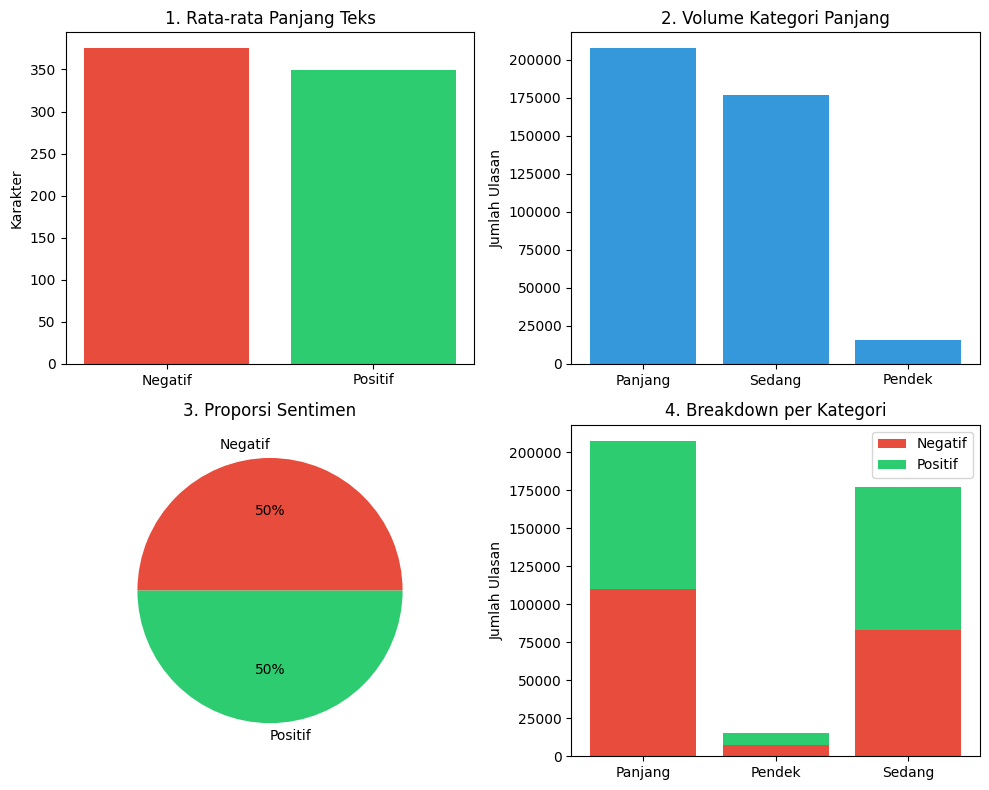

In [27]:
df_visual = (
    df.withColumn("panjang_teks", length("text"))
    .withColumn(
        "kategori_panjang",
        when(col("panjang_teks") < 100, "Pendek")
        .when(col("panjang_teks").between(100, 300), "Sedang")
        .otherwise("Panjang"),
    )
    .withColumn(
        "sentimen", when(col("label") == 1, "Negatif").otherwise("Positif")
    )
)

pdf = df_visual.select("sentimen", "kategori_panjang", "panjang_teks").toPandas()

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

df_avg = pdf.groupby("sentimen")["panjang_teks"].mean()
axes[0, 0].bar(df_avg.index, df_avg.values, color=["#e74c3c", "#2ecc71"])
axes[0, 0].set_title("1. Rata-rata Panjang Teks")
axes[0, 0].set_ylabel("Karakter")

df_cat = pdf["kategori_panjang"].value_counts()
axes[0, 1].bar(df_cat.index, df_cat.values, color="#3498db")
axes[0, 1].set_title("2. Volume Kategori Panjang")
axes[0, 1].set_ylabel("Jumlah Ulasan")

df_sent = pdf["sentimen"].value_counts()
axes[1, 0].pie(
    df_sent.values,
    labels=df_sent.index,
    autopct="%1.0f%%",
    colors=["#e74c3c", "#2ecc71"],
)
axes[1, 0].set_title("3. Proporsi Sentimen")

df_pivot = pdf.groupby(["kategori_panjang", "sentimen"]).size().unstack().fillna(0)
axes[1, 1].bar(df_pivot.index, df_pivot["Negatif"], label="Negatif", color="#e74c3c")
axes[1, 1].bar(df_pivot.index, df_pivot["Positif"], bottom=df_pivot["Negatif"], label="Positif", color="#2ecc71")
axes[1, 1].set_title("4. Breakdown per Kategori")
axes[1, 1].set_ylabel("Jumlah Ulasan")
axes[1, 1].legend()

plt.tight_layout()
plt.show()